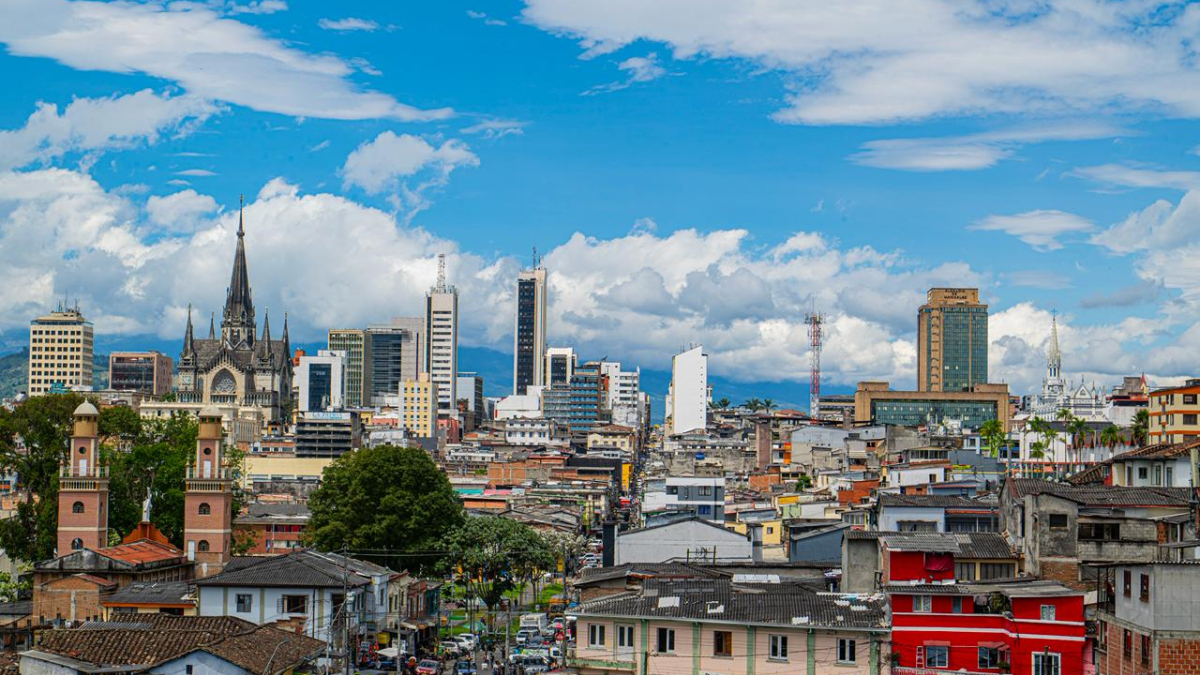

In [8]:
from IPython.display import display, Image

with open("img/manizales.jpg", "rb") as archivo:
    imagen = archivo.read()

display(Image(data=imagen, format="jpeg", width=900))

# Taller práctico: Análisis exploratorio y visualización de datos
## Distribución de estratos socioeconómicos por comuna y barrio — Manizales, Caldas

**Fuente de datos:** conjunto `estratos_manizales.csv`, descargado de Kaggle:  
https://www.kaggle.com/datasets/cfccfelipe/rent-caldas-colombia

**Propósito:** realizar una exploración descriptiva de los datos, construir visualizaciones adicionales a las gráficas introductorias trabajadas en clase e interpretar los resultados para formular conclusiones.

### Preguntas orientadoras
1. ¿Cómo se distribuyen los estratos socioeconómicos en los barrios registrados?
2. ¿Qué comunas presentan mayor diversidad de estratos?
3. ¿En qué comunas se observan valores centrales más altos o más bajos?
4. ¿Se identifican valores atípicos en la distribución del estrato?

### Alcance y precauciones
Cada fila representa un registro de barrio. Por tanto, los porcentajes y promedios de este notebook describen **la cantidad de barrios registrados**, no la cantidad de habitantes, viviendas ni hogares. El estrato es una variable ordinal (sus categorías tienen un orden), por lo que los promedios se usan únicamente como resumen descriptivo y deben interpretarse con cautela. Los resultados no permiten inferir ingresos individuales ni condiciones socioeconómicas de cada habitante.

## 1. Preparación del entorno y carga de los datos

El archivo CSV está incorporado dentro de este notebook para facilitar su ejecución sin depender de una ruta específica. Si se desea trabajar con una versión externa, también se puede dejar `estratos_manizales.csv` en la misma carpeta del notebook.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from io import BytesIO
import base64
from IPython.display import display


plt.style.use("ggplot")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["font.family"] = "DejaVu Sans"

try:
    df = pd.read_csv("estratos_manizales.csv")
    origen_datos = "Archivo externo: estratos_manizales.csv"
except FileNotFoundError:
   
    contenido = base64.b64decode("77u/aWQsY29tdW5hLGlkZW50LGJhcnJpbyxjb2RpZ28sbm9tYnJlLGVzdHJhdG8NCjIsQXRhcmRlY2VyZXMsMTAxLENJVURBREVMQSBMQSBMSU5EQSwxMDEwMCxDSVVEQURFTEEgTEEgTElOREEsMg0KNCxBdGFyZGVjZXJlcywxMDIsQkVMTEEgTU9OVEHCpUEsMTAyMDAsQkVMTEEgTU9OVEHDkUEsMw0KNyxBdGFyZGVjZXJlcywxMDMsU0FDQVRJTiwxMDMwMCxTQUNBVElOLDENCjgsQXRhcmRlY2VyZXMsMTA0LFZJTExBUElMQVIsMTA0MDAsVklMTEFQSUxBUiw0DQoxNyxBdGFyZGVjZXJlcywxMDUsQ0hJUFJFLDEwNTAwLENISVBSRSw0DQoyMSxBdGFyZGVjZXJlcywxMDYsQ0FNUE9IRVJNT1NPLDEwNjAwLENBTVBPSEVSTU9TTyw0DQoyNyxBdGFyZGVjZXJlcywxMDcsTU9SUk9HQUNITywxMDcwMCxNT1JST0dBQ0hPLDINCjMwLEF0YXJkZWNlcmVzLDEwOCxMQSBGUkFOQ0lBLDEwODAwLExBIEZSQU5DSUEsNg0KMzYsQXRhcmRlY2VyZXMsMTA5LExPUyBBTENBWkFSRVMsMTA5MDAsTE9TIEFMQ0FaQVJFUyw0DQo0MixBdGFyZGVjZXJlcywxMTAsQVJFTklMTE8sMTEwMDAsQVJFTklMTE8sNA0KNDMsU2FuIEpvc8WgLDIwMSxBU0lTLDIwMTAwLEFTSVMsMQ0KNDUsU2FuIEpvc8WgLDIwMixBVkFOWkFEQSwyMDIwMCxBVkFOWkFEQSwxDQo0OCxTYW4gSm9zxaAsMjAzLFNBTiBJR05BQ0lPLDIwMzAwLFNBTiBJR05BQ0lPLDINCjQ5LFNhbiBKb3PFoCwyMDQsR0FMQU4sMjA0MDAsR0FMQU4sMg0KNTMsU2FuIEpvc8WgLDIwNSxFU1RSQURBLDIwNTAwLEVTVFJBREEsMQ0KNTUsU2FuIEpvc8WgLDIwNixERUxJQ0lBUywyMDYwMCxERUxJQ0lBUywzDQo1NixTYW4gSm9zxaAsMjA3LFNBTiBKT1NFLDIwNzAwLFNBTiBKT1NFLDMNCjU4LFNhbiBKb3PFoCwyMDgsQ09MT04sMjA4MDAsQ09MT04sMw0KNjAsQ3VtYW5kYXksMzAxLExBUyBBTUVSSUNBUywzMDEwMCxMQVMgQU1FUklDQVMsMw0KMjQxLEN1bWFuZGF5LDMwMixMT1MgQUdVU1RJTk9TLDMwMjAwLExPUyBBR1VTVElOT1MsMw0KMjQyLEN1bWFuZGF5LDMwMyxDRU5UUk8sMzAzMDAsQ0VOVFJPLDMNCjI0NCxDdW1hbmRheSwzMDQsU0FOIEpPQVFVSU4sMzA0MDAsU0FOIEpPQVFVSU4sMw0KMjQ1LEN1bWFuZGF5LDMwNSxDQU1QT0FNT1IsMzA1MDAsQ0FNUE9BTU9SLDMNCjI0NyxDdW1hbmRheSwzMDYsRlVOREFET1JFUywzMDYwMCxGVU5EQURPUkVTLDMNCjI0OCxMYSBFc3RhY2nCom4sNDAxLFNBTlRBIEhFTEVOQSw0MDEwMCxTQU5UQSBIRUxFTkEsMw0KMjU0LExhIEVzdGFjacKibiw0MDIsTE9TIENFRFJPUyw0MDIwMCxMT1MgQ0VEUk9TLDMNCjI1NixMYSBFc3RhY2nCom4sNDAzLFNBTiBKT1JHRSw0MDMwMCxTQU4gSk9SR0UsNA0KMjU3LExhIEVzdGFjacKibiw0MDQsRUwgU09MLDQwNDAwLEVMIFNPTCw0DQoyNjAsTGEgRXN0YWNpwqJuLDQwNSxMQSBBUkdFTlRJTkEsNDA1MDAsTEEgQVJHRU5USU5BLDMNCjI2MSxMYSBFc3RhY2nCom4sNDA2LExBIEFTVU5DSU9OLDQwNjAwLExBIEFTVU5DSU9OLDMNCjI2MyxMYSBFc3RhY2nCom4sNDA3LFZFUlNBTExFUyw0MDcwMCxWRVJTQUxMRVMsNA0KMjY1LExhIEVzdGFjacKibiw0MDgsRUwgQ0FNUElOLDQwODAwLEVMIENBTVBJTiw0DQoyNjYsTGEgRXN0YWNpwqJuLDQwOSxMTEVSQVMsNDA5MDAsTExFUkFTLDMNCjI2OCxDaXVkYWRkZWxhIGRlbCBub3J0ZSw1MDEsUFVFUlRBIERFTCBTT0wgLDUwMTAwLFBVRVJUQSBERUwgU09MICwzDQoyNjksQ2l1ZGFkZGVsYSBkZWwgbm9ydGUsNTAyLFNJRVJSQSBNT1JFTkEsNTAyMDAsU0lFUlJBIE1PUkVOQSwyDQoyNzAsQ2l1ZGFkZGVsYSBkZWwgbm9ydGUsNTAzLEVMIENBUklCRSw1MDMwMCxFTCBDQVJJQkUsMg0KMjcyLENpdWRhZGRlbGEgZGVsIG5vcnRlLDUwNCxTQU4gQ0FZRVRBTk8sNTA0MDAsU0FOIENBWUVUQU5PLDINCjI3MyxDaXVkYWRkZWxhIGRlbCBub3J0ZSw1MDUsQk9TUVVFUyBERUwgTk9SVEUsNTA1MDAsQk9TUVVFUyBERUwgTk9SVEUsMg0KMjc3LENpdWRhZGRlbGEgZGVsIG5vcnRlLDUwNixTQU4gU0VCQVNUSUFOLDUwNjAwLFNBTiBTRUJBU1RJQU4sMQ0KMjgyLENpdWRhZGRlbGEgZGVsIG5vcnRlLDUwNyxGQU5OWSBHT05aQUxFWiw1MDcwMCxGQU5OWSBHT05aQUxFWiwyDQoyODMsQ2l1ZGFkZGVsYSBkZWwgbm9ydGUsNTA4LEFMVE9TIERFIENBUFJJLDUwODAwLEFMVE9TIERFIENBUFJJLDMNCjI4NyxDaXVkYWRkZWxhIGRlbCBub3J0ZSw1MDksVklMTEEgSlVMSUEsNTA5MDAsVklMTEEgSlVMSUEsMg0KMjg4LENpdWRhZGRlbGEgZGVsIG5vcnRlLDUxMCxQRVJBTE9OU08sNTEwMDAsUEVSQUxPTlNPLDINCjI5MCxFY290dXLCoXN0aWNvIENlcnJvIGRlIE9ybyw2MDEsVklWRVJPUyw2MDEwMCxWSVZFUk9TLDINCjI5NSxFY290dXLCoXN0aWNvIENlcnJvIGRlIE9ybyw2MDIsTEEgQ1VNQlJFLDYwMjAwLExBIENVTUJSRSwyDQoyOTYsRWNvdHVywqFzdGljbyBDZXJybyBkZSBPcm8sNjAzLE1JTklUQVMsNjAzMDAsTUlOSVRBUywzDQoyOTcsRWNvdHVywqFzdGljbyBDZXJybyBkZSBPcm8sNjA0LEJBSkEgU1VJWkEsNjA0MDAsQkFKQSBTVUlaQSw0DQo2MSxFY290dXLCoXN0aWNvIENlcnJvIGRlIE9ybyw2MDUsQUxUQSBTVUlaQSw2MDUwMCxBTFRBIFNVSVpBLDUNCjYzLEVjb3R1csKhc3RpY28gQ2Vycm8gZGUgT3JvLDYwNixSRVNJREVOQ0lBUyBNQU5JWkFMRVMsNjA2MDAsUkVTSURFTkNJQVMgTUFOSVpBTEVTLDQNCjY0LEVjb3R1csKhc3RpY28gQ2Vycm8gZGUgT3JvLDYwNyxDT0xTRUdVUk9TLDYwNzAwLENPTFNFR1VST1MsNA0KNjcsRWNvdHVywqFzdGljbyBDZXJybyBkZSBPcm8sNjA4LExBIFRPU0NBTkEsNjA4MDAsTEEgVE9TQ0FOQSwzDQo2OSxFY290dXLCoXN0aWNvIENlcnJvIGRlIE9ybyw2MDksTEEgU1VMVEFOQSw2MDkwMCxMQSBTVUxUQU5BLDMNCjcwLEVjb3R1csKhc3RpY28gQ2Vycm8gZGUgT3JvLDYxMCxCT1NRVUVTIERFIE5JWkEsNjEwMDAsQk9TUVVFUyBERSBOSVpBLDQNCjc3LFRlc29yaXRvLDcwMSxTQU4gTUFSQ0VMLDcwMTAwLFNBTiBNQVJDRUwsNQ0KODMsVGVzb3JpdG8sNzAyLEFMSEFNQlJBLDcwMjAwLEFMSEFNQlJBLDYNCjg2LFRlc29yaXRvLDcwMyxDRVJST1MgREUgTEEgQUxIQU1CUkEsNzAzMDAsQ0VSUk9TIERFIExBIEFMSEFNQlJBLDYNCjg4LFRlc29yaXRvLDcwNCxNQUxURVJJQSw3MDQwMCxNQUxURVJJQSwyDQo5MCxUZXNvcml0byw3MDUsWk9OQSBJTkRVU1RSSUFMLDcwNTAwLFpPTkEgSU5EVVNUUklBTCwyDQo5MixUZXNvcml0byw3MDYsQ0FTRVJJTyBMQSBFTkVBLDcwNjAwLENBU0VSSU8gTEEgRU5FQSw0DQo5NyxUZXNvcml0byw3MDcsTEEgRU5FQSw3MDcwMCxMQSBFTkVBLDMNCjEwMSxUZXNvcml0byw3MDgsTFVTSVRBTklBLDcwODAwLExVU0lUQU5JQSwzDQoxMDIsUGFsb2dyYW5kZSw4MDEsTEVPTk9SQSw4MDEwMCxMRU9OT1JBLDQNCjEwNCxQYWxvZ3JhbmRlLDgwMixMT1MgUk9TQUxFUyw4MDIwMCxMT1MgUk9TQUxFUyw1DQoxMDUsUGFsb2dyYW5kZSw4MDMsTEEgUkFNQkxBLDgwMzAwLExBIFJBTUJMQSw1DQoxMDYsUGFsb2dyYW5kZSw4MDQsTEFVUkVMRVMsODA0MDAsTEFVUkVMRVMsNQ0KMTA3LFBhbG9ncmFuZGUsODA1LFBBTE9HUkFOREUsODA1MDAsUEFMT0dSQU5ERSw1DQoxMTEsUGFsb2dyYW5kZSw4MDYsTEEgRVNUUkVMTEEsODA2MDAsTEEgRVNUUkVMTEEsNQ0KMTEyLFBhbG9ncmFuZGUsODA3LEJFTEVOLDgwNzAwLEJFTEVOLDQNCjExMyxQYWxvZ3JhbmRlLDgwOCxHVUFZQUNBTkVTLDgwODAwLEdVQVlBQ0FORVMsNg0KMTE0LFBhbG9ncmFuZGUsODA5LEFSQk9MRURBLDgwOTAwLEFSQk9MRURBLDQNCjExNixQYWxvZ3JhbmRlLDgxMCxQQUxFUk1PLDgxMDAwLFBBTEVSTU8sNg0KMTE5LFBhbG9ncmFuZGUsODExLENBTUVMSUEsODExMDAsQ0FNRUxJQSw2DQoxNzgsUGFsb2dyYW5kZSw4MTIsU0FOQ0FOQ0lPLDgxMjAwLFNBTkNBTkNJTyw2DQoxODIsUGFsb2dyYW5kZSw4MTMsTUlMQU4sODEzMDAsTUlMQU4sNg0KMTg1LFBhbG9ncmFuZGUsODE0LEVMIFRSRUJPTCw4MTQwMCxFTCBUUkVCT0wsNg0KMTkzLFVuaXZlcnNpdGFyaWEsOTAxLEJFVEFOSUEsOTAxMDAsQkVUQU5JQSwyDQoxOTQsVW5pdmVyc2l0YXJpYSw5MDIsRkFUSU1BLDkwMjAwLEZBVElNQSwzDQoxOTUsVW5pdmVyc2l0YXJpYSw5MDMsVklWSUVOREEgUE9QVUxBUiw5MDMwMCxWSVZJRU5EQSBQT1BVTEFSLDENCjE5OCxVbml2ZXJzaXRhcmlhLDkwNCxQSU8gWElJLDkwNDAwLFBJTyBYSUksMg0KMTk5LFVuaXZlcnNpdGFyaWEsOTA1LEtFTk5FRFksOTA1MDAsS0VOTkVEWSwyDQoyMDUsVW5pdmVyc2l0YXJpYSw5MDYsQ0FNSUxPIFRPUlJFUyw5MDYwMCxDQU1JTE8gVE9SUkVTLDMNCjIwOCxVbml2ZXJzaXRhcmlhLDkwNyxMQVMgQ09MSU5BUyw5MDcwMCxMQVMgQ09MSU5BUywzDQoyMTEsVW5pdmVyc2l0YXJpYSw5MDgsTUFMSEFCQVIsOTA4MDAsTUFMSEFCQVIsMw0KMjEzLFVuaXZlcnNpdGFyaWEsOTA5LEFSQU5KVUVaLDkwOTAwLEFSQU5KVUVaLDMNCjIxNixMYSBGdWVudGUsMTAwMSxVUklCRSwxMDAxMDAsVVJJQkUsMw0KMjE5LExhIEZ1ZW50ZSwxMDAyLFZFTEVaLDEwMDIwMCxWRUxFWiwzDQoyMjEsTGEgRnVlbnRlLDEwMDMsQ09MT01CSUEsMTAwMzAwLENPTE9NQklBLDMNCjIyMixMYSBGdWVudGUsMTAwNCxFTCBQUkFETywxMDA0MDAsRUwgUFJBRE8sMw0KMjIzLExhIEZ1ZW50ZSwxMDA1LEJBSk8gUFJBRE8sMTAwNTAwLEJBSk8gUFJBRE8sMw0KMjI0LExhIEZ1ZW50ZSwxMDA2LEdPTlpBTEVaLDEwMDYwMCxHT05aQUxFWiwxDQoyMjUsTGEgRnVlbnRlLDEwMDcsUEVSU0lBLDEwMDcwMCxQRVJTSUEsMg0KMjMxLExhIEZ1ZW50ZSwxMDA4LEdVQU1BTCwxMDA4MDAsR1VBTUFMLDMNCjIzNCxMYSBGdWVudGUsMTAwOSxFTCBQQVJBSVNPLDEwMDkwMCxFTCBQQVJBSVNPLDENCjIzNSxMYSBGdWVudGUsMTAxMCxWSUxMQUNBUk1FTlpBLDEwMTAwMCxWSUxMQUNBUk1FTlpBLDQNCjIzNixMYSBGdWVudGUsMTAxMSxBUlJBWUFORVMsMTAxMTAwLEFSUkFZQU5FUywxDQoyMzcsTGEgRnVlbnRlLDEwMTIsQ0VSVkFOVEVTLDEwMTIwMCxDRVJWQU5URVMsMw0KMTIxLExhIEZ1ZW50ZSwxMDEzLE5FVkFETywxMDEzMDAsTkVWQURPLDINCjEyNSxMYSBGdWVudGUsMTAxNCxNQVJNQVRPLDEwMTQwMCxNQVJNQVRPLDENCjEyOCxMYSBNYWNhcmVuYSwxMTAxLFNBTiBBTlRPTklPLDExMDEwMCxTQU4gQU5UT05JTywzDQoxMjksTGEgTWFjYXJlbmEsMTEwMiwyMCBERSBKVUxJTywxMTAyMDAsMjAgREUgSlVMSU8sMg0KMTMxLExhIE1hY2FyZW5hLDExMDMsRUwgQ0FSTUVOLDExMDMwMCxFTCBDQVJNRU4sMQ0KMTM2LExhIE1hY2FyZW5hLDExMDQsRUwgQk9TUVVFLDExMDQwMCxFTCBCT1NRVUUsMg0KMTM4LExhIE1hY2FyZW5hLDExMDUsQ0FTVEVMTEFOQSwxMTA1MDAsQ0FTVEVMTEFOQSw0DQoxMzksTGEgTWFjYXJlbmEsMTEwNixCVUVOQSBFU1BFUkFOWkEsMTEwNjAwLEJVRU5BIEVTUEVSQU5aQSwyDQoxNDAsTGEgTWFjYXJlbmEsMTEwNyxOT0dBTEVTLDExMDcwMCxOT0dBTEVTLDMNCjE0MixMYSBNYWNhcmVuYSwxMTA4LFBBTk9SQU1BLDExMDgwMCxQQU5PUkFNQSwyDQoxNDUsTGEgTWFjYXJlbmEsMTEwOSxDRU5URU5BUklPLDExMDkwMCxDRU5URU5BUklPLDMNCjE0OCxMYSBNYWNhcmVuYSwxMTEwLEVTVEFNQlVMLDExMTAwMCxFU1RBTUJVTCwzDQoxNTQsRG9jZSwxMjAxLFNPTEZFUklOTywxMjAxMDAsU09MRkVSSU5PLDINCjE1NyxEb2NlLDEyMDIsTEEgQ0FST0xBLDEyMDIwMCxMQSBDQVJPTEEsMw0KMTY5LERvY2UsMTIwMyxWSUxMQUhFUk1PU0EsMTIwMzAwLFZJTExBSEVSTU9TQSwyDQoxNzMsRG9jZSwxMjA0LENPTVVORVJPUywxMjA0MDAsQ09NVU5FUk9TLDINCjE3NCxEb2NlLDEyMDUsUE9SVkVOSVIsMTIwNTAwLFBPUlZFTklSLDINCjE3NixEb2NlLDEyMDYsU0lOQUksMTIwNjAwLFNJTkFJLDINCg==")
    df = pd.read_csv(BytesIO(contenido))
    origen_datos = "CSV incorporado en el notebook"

print("Origen de los datos:", origen_datos)
print("Dimensiones:", df.shape)
display(df.head())

Origen de los datos: CSV incorporado en el notebook
Dimensiones: (114, 7)


,id,comuna,ident,barrio,codigo,nombre,estrato
0,2,Atardeceres,101,CIUDADELA LA LINDA,10100,CIUDADELA LA LINDA,2
1,4,Atardeceres,102,BELLA MONTA¥A,10200,BELLA MONTAÑA,3
2,7,Atardeceres,103,SACATIN,10300,SACATIN,1
3,8,Atardeceres,104,VILLAPILAR,10400,VILLAPILAR,4
4,17,Atardeceres,105,CHIPRE,10500,CHIPRE,4


## 2. Exploración inicial de los datos

Se revisan las dimensiones, los nombres de las columnas, los tipos de datos y una muestra de registros. Esto permite reconocer qué información contiene el conjunto antes de realizar cálculos o gráficos.

In [10]:
print("Número de filas:", df.shape[0])
print("Número de columnas:", df.shape[1])
print("\\nColumnas:")
print(df.columns.tolist())
print("\\nTipos de datos:")
display(df.dtypes.to_frame("tipo de dato"))
print("\\nPrimeros cinco registros:")
display(df.head())
print("\\nResumen de variables numéricas:")
display(df.describe().T)

Número de filas: 114
Número de columnas: 7
\nColumnas:
['id', 'comuna', 'ident', 'barrio', 'codigo', 'nombre', 'estrato']
\nTipos de datos:


,tipo de dato
id,int64
comuna,str
ident,int64
barrio,str
codigo,int64
nombre,str
estrato,int64


\nPrimeros cinco registros:


,id,comuna,ident,barrio,codigo,nombre,estrato
0,2,Atardeceres,101,CIUDADELA LA LINDA,10100,CIUDADELA LA LINDA,2
1,4,Atardeceres,102,BELLA MONTA¥A,10200,BELLA MONTAÑA,3
2,7,Atardeceres,103,SACATIN,10300,SACATIN,1
3,8,Atardeceres,104,VILLAPILAR,10400,VILLAPILAR,4
4,17,Atardeceres,105,CHIPRE,10500,CHIPRE,4


\nResumen de variables numéricas:


,count,mean,std,min,25%,50%,75%,max
id,114.0,159.500000,86.245918,2.0,88.50,155.5,236.75,297.0
ident,114.0,673.105263,334.458627,101.0,405.25,704.5,1001.75,1206.0
codigo,114.0,67310.526316,33445.862658,10100.0,40525.00,70450.0,100175.00,120600.0
estrato,114.0,3.078947,1.331343,1.0,2.00,3.0,4.00,6.0


## 3. Limpieza y calidad de los datos

Se comprueba la presencia de valores nulos, filas duplicadas y posibles duplicados en los identificadores. También se normalizan algunos nombres de comunas que aparecen con problemas de codificación de caracteres en el archivo original. Esta corrección es textual: no modifica los valores de estrato ni los identificadores.

In [11]:
print("Valores nulos por columna:")
display(df.isna().sum().to_frame("valores nulos"))
print("Filas duplicadas completas:", df.duplicated().sum())
print("Identificadores id duplicados:", df["id"].duplicated().sum())
print("Códigos de barrio duplicados:", df["codigo"].duplicated().sum())


correcciones = {
    "San JosŠ": "San José",
    "La Estaci¢n": "La Estación",
    "Ecotur¡stico Cerro de Oro": "Ecoturístico Cerro de Oro",
    "Ciudaddela del norte": "Ciudadela del Norte"
}
df["comuna"] = df["comuna"].replace(correcciones)


df["comuna"] = df["comuna"].astype(str).str.strip()
df["barrio"] = df["barrio"].astype(str).str.strip()
df["nombre"] = df["nombre"].astype(str).str.strip()

print("Comunas después de la normalización:", df["comuna"].nunique())
print("Valores de estrato encontrados:", sorted(df["estrato"].dropna().unique()))

Valores nulos por columna:


,valores nulos
id,0
comuna,0
ident,0
barrio,0
codigo,0
nombre,0
estrato,0


Filas duplicadas completas: 0
Identificadores id duplicados: 0
Códigos de barrio duplicados: 0
Comunas después de la normalización: 12
Valores de estrato encontrados: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


## 4. Análisis descriptivo de las variables

La variable `estrato` es el foco del análisis. Se calcula su frecuencia absoluta y relativa, además de medidas descriptivas como media, mediana, moda, mínimo y máximo. Las columnas `id`, `ident` y `codigo` funcionan como identificadores, por lo que no se interpretan como magnitudes.

In [12]:
frecuencia = df["estrato"].value_counts().sort_index().rename("barrios")
frecuencia_relativa = (frecuencia / len(df) * 100).rename("porcentaje")
tabla_estratos = pd.concat([frecuencia, frecuencia_relativa], axis=1)
display(tabla_estratos.round(2))

resumen_estrato = df["estrato"].describe()
print("Media:", round(df["estrato"].mean(), 2))
print("Mediana:", df["estrato"].median())
print("Moda:", df["estrato"].mode().tolist())
print("Rango:", int(df["estrato"].max() - df["estrato"].min()))
print("Desviación estándar:", round(df["estrato"].std(), 2))

,barrios,porcentaje
estrato,,
1,11,9.65
2,29,25.44
3,39,34.21
4,19,16.67
5,7,6.14
6,9,7.89


Media: 3.08
Mediana: 3.0
Moda: [3]
Rango: 5
Desviación estándar: 1.33


## 5. Visualizaciones adicionales

Las siguientes visualizaciones amplían la exploración más allá de los gráficos introductorios habituales. Cada gráfico incluye una interpretación que se puede contrastar con los resultados observados.

### Visualización 1. Diagrama de cajas y bigotes del estrato por comuna

**¿Qué permite observar?** La mediana, la dispersión intercuartílica y posibles valores atípicos de los estratos registrados en cada comuna. Es el diagrama de cajas y bigotes solicitado en la actividad.

**Nota:** como los estratos son valores discretos y ordinales, las cajas resumen la distribución de los registros; no representan una escala continua de bienestar.

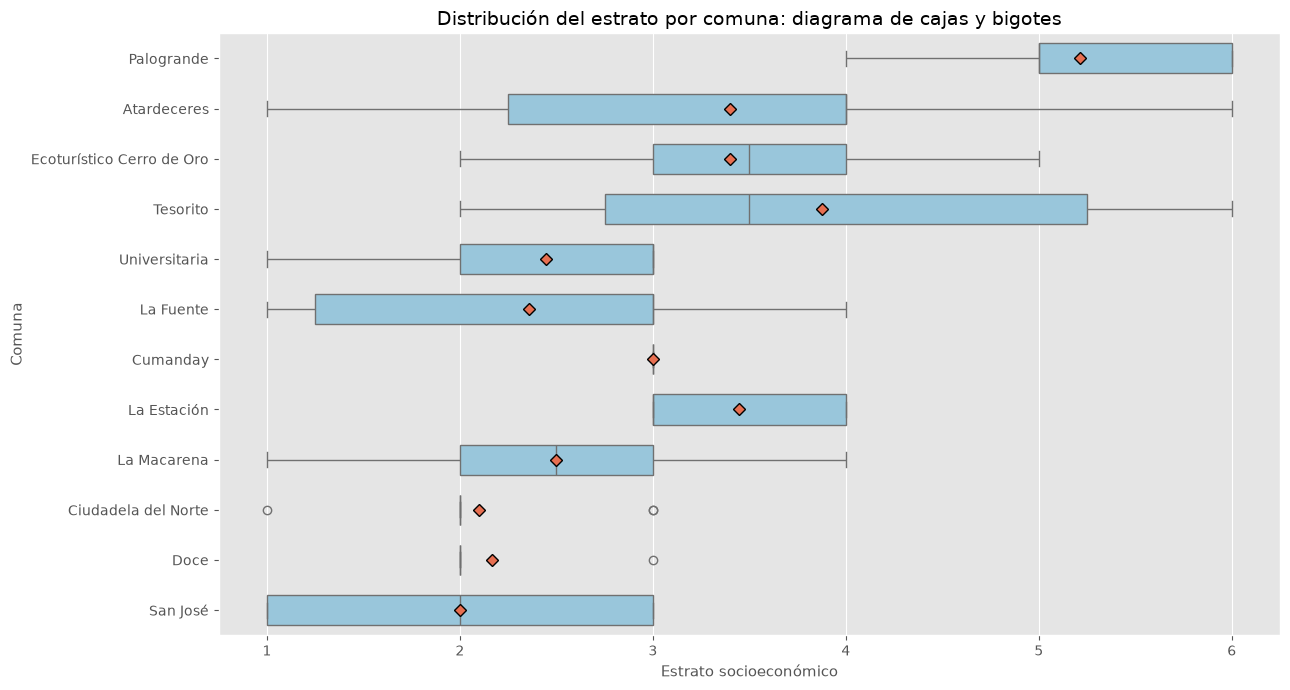

In [13]:
orden_comunas = (df.groupby("comuna")["estrato"].median()
                 .sort_values(ascending=False).index)

plt.figure(figsize=(13, 7))
sns.boxplot(data=df, x="estrato", y="comuna", order=orden_comunas,
            color="#8ecae6", width=0.6, showmeans=True,
            meanprops={"marker": "D", "markerfacecolor": "#e76f51",
                       "markeredgecolor": "black", "markersize": 6})
plt.title("Distribución del estrato por comuna: diagrama de cajas y bigotes")
plt.xlabel("Estrato socioeconómico")
plt.ylabel("Comuna")
plt.xticks(range(1, 7))
plt.tight_layout()
plt.show()

**Interpretación:** la línea central de cada caja representa la mediana. Las cajas más amplias indican mayor dispersión de los estratos entre los barrios registrados en esa comuna. Los puntos que aparecen fuera de los bigotes pueden considerarse valores atípicos según la regla de 1,5 veces el rango intercuartílico. La comuna de Palogrande presenta una mediana elevada frente a la mayoría de comunas; otras comunas se concentran en estratos inferiores. La presencia de un punto atípico no implica un error: puede corresponder a un barrio con un estrato diferente al predominante en su comuna.

### Visualización 2. Mapa de calor: cantidad de barrios por comuna y estrato

**¿Qué permite observar?** La concentración de registros en cada combinación de comuna y estrato. Los colores más intensos representan mayor cantidad de barrios en esa combinación.

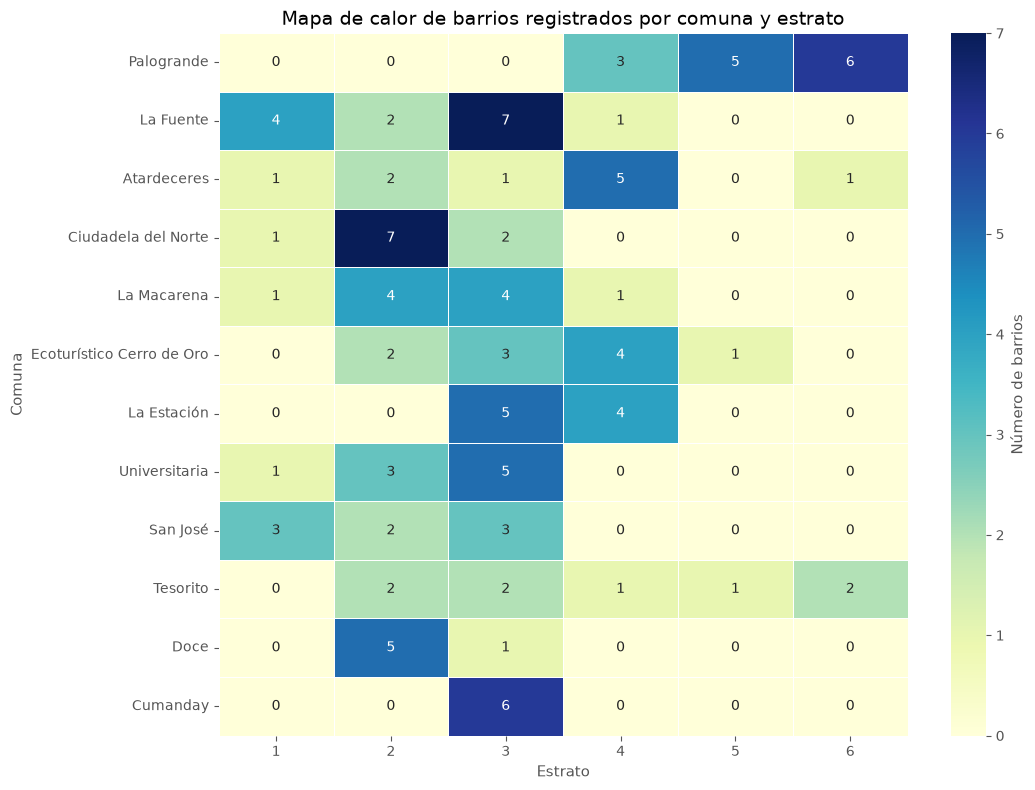

In [14]:
tabla_cruzada = pd.crosstab(df["comuna"], df["estrato"]).reindex(columns=range(1, 7), fill_value=0)
tabla_cruzada = tabla_cruzada.loc[tabla_cruzada.sum(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(11, 8))
sns.heatmap(tabla_cruzada, annot=True, fmt="d", cmap="YlGnBu",
            linewidths=0.5, cbar_kws={"label": "Número de barrios"})
plt.title("Mapa de calor de barrios registrados por comuna y estrato")
plt.xlabel("Estrato")
plt.ylabel("Comuna")
plt.tight_layout()
plt.show()

**Interpretación:** el mapa de calor permite identificar patrones que no se aprecian fácilmente en una tabla extensa. Por ejemplo, Palogrande concentra sus registros en los estratos 4, 5 y 6, mientras que comunas como San José y Ciudadela del Norte presentan mayor concentración en estratos 1 y 2. Cumanday registra únicamente barrios de estrato 3 en este conjunto. Estas observaciones describen los registros disponibles, no necesariamente todos los barrios o habitantes de cada comuna.

### Visualización 3. Barras apiladas al 100 %: composición porcentual de cada comuna

**¿Qué permite observar?** La proporción de barrios de cada estrato dentro de cada comuna. Al normalizar cada barra al 100 %, se pueden comparar comunas con diferente número de registros.

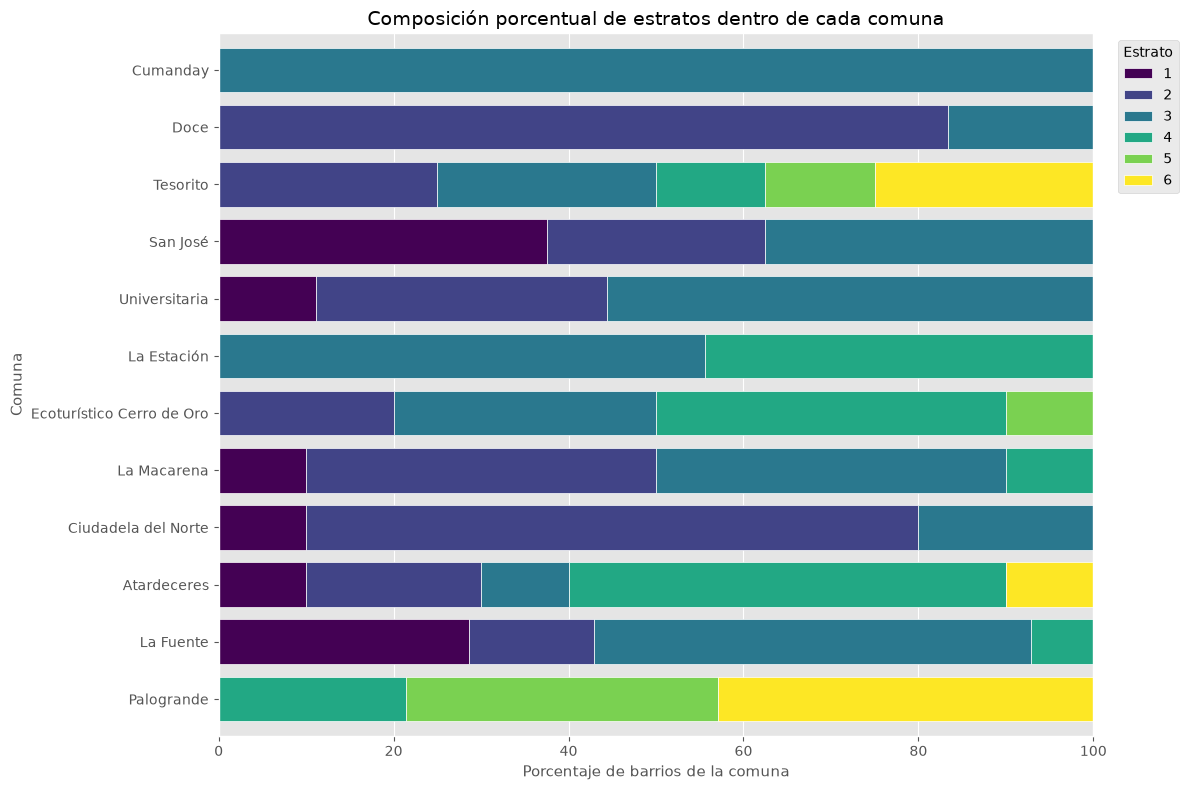

In [15]:
composicion = pd.crosstab(df["comuna"], df["estrato"], normalize="index") * 100
composicion = composicion.reindex(tabla_cruzada.index)

ax = composicion.plot(kind="barh", stacked=True, figsize=(12, 8),
                      colormap="viridis", edgecolor="white", width=0.78)
ax.set_title("Composición porcentual de estratos dentro de cada comuna")
ax.set_xlabel("Porcentaje de barrios de la comuna")
ax.set_ylabel("Comuna")
ax.set_xlim(0, 100)
ax.legend(title="Estrato", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Interpretación:** esta gráfica compara la composición interna de las comunas sin que el tamaño de la muestra de cada una domine la lectura. Se observa una composición marcadamente alta en estratos 4 a 6 en Palogrande. En contraste, San José y Ciudadela del Norte se concentran en los estratos 1 y 2. La Fuente y La Macarena muestran una distribución más repartida entre varios estratos.

### Visualización 4. Gráfico de puntos: estrato promedio por comuna y cantidad de barrios

**¿Qué permite observar?** Compara el promedio descriptivo del estrato entre comunas. El tamaño de cada punto representa cuántos barrios están registrados en esa comuna. Se utiliza como resumen exploratorio, recordando que el estrato es una variable ordinal.

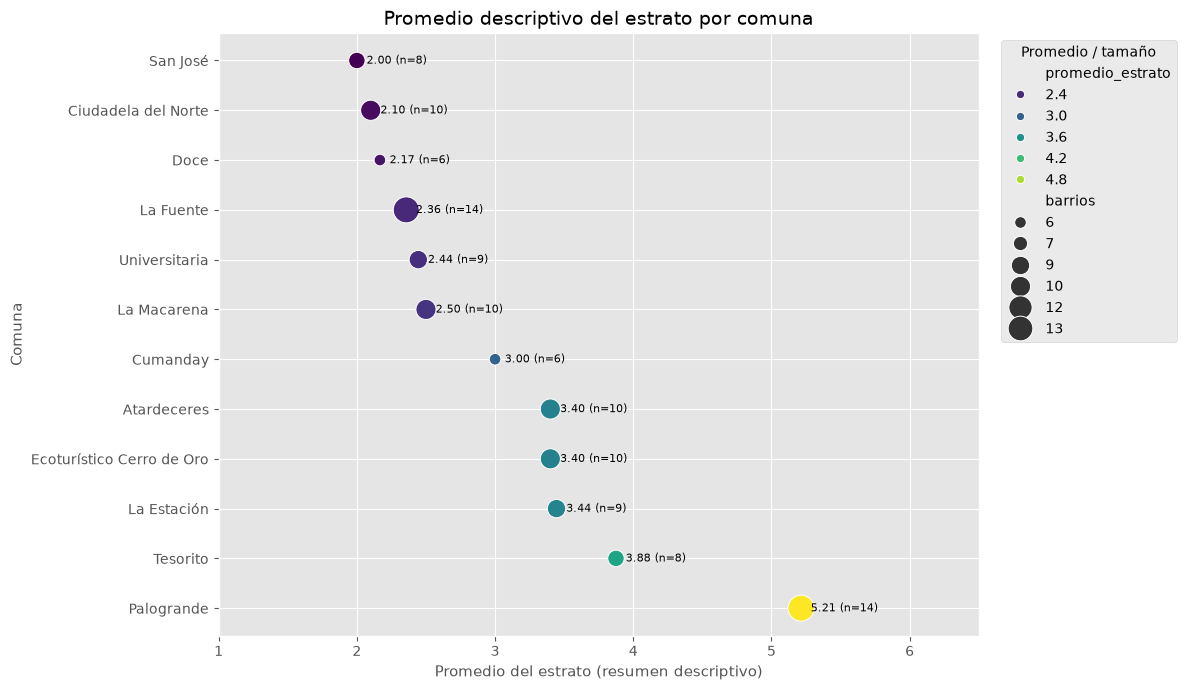

In [16]:
resumen_comunas = (df.groupby("comuna")
                   .agg(barrios=("estrato", "size"),
                        promedio_estrato=("estrato", "mean"),
                        mediana=("estrato", "median"))
                   .sort_values("promedio_estrato"))

plt.figure(figsize=(12, 7))
sns.scatterplot(data=resumen_comunas, x="promedio_estrato", y=resumen_comunas.index,
                size="barrios", sizes=(70, 350), hue="promedio_estrato",
                palette="viridis", legend="brief")
for comuna, fila in resumen_comunas.iterrows():
    plt.annotate(f"{fila['promedio_estrato']:.2f} (n={int(fila['barrios'])})",
                 (fila["promedio_estrato"], comuna),
                 xytext=(7, 0), textcoords="offset points", va="center", fontsize=8)
plt.title("Promedio descriptivo del estrato por comuna")
plt.xlabel("Promedio del estrato (resumen descriptivo)")
plt.ylabel("Comuna")
plt.xlim(1, 6.5)
plt.legend(title="Promedio / tamaño", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Interpretación:** Palogrande presenta el promedio descriptivo más alto, mientras que San José presenta el más bajo. El tamaño de los puntos recuerda que las comunas no tienen el mismo número de barrios registrados. Por eso, las diferencias de promedio deben leerse junto con el tamaño de cada grupo y no como una clasificación definitiva de la calidad de vida de sus habitantes.

### Visualización 5. Diagrama de violín: distribución de estratos por comuna

**¿Qué permite observar?** Muestra la concentración relativa de observaciones a lo largo de la escala de estratos y complementa el diagrama de cajas. Se incluye como visualización exploratoria; al tratarse de una variable discreta con pocos registros por comuna, la forma suavizada del violín debe interpretarse con prudencia.

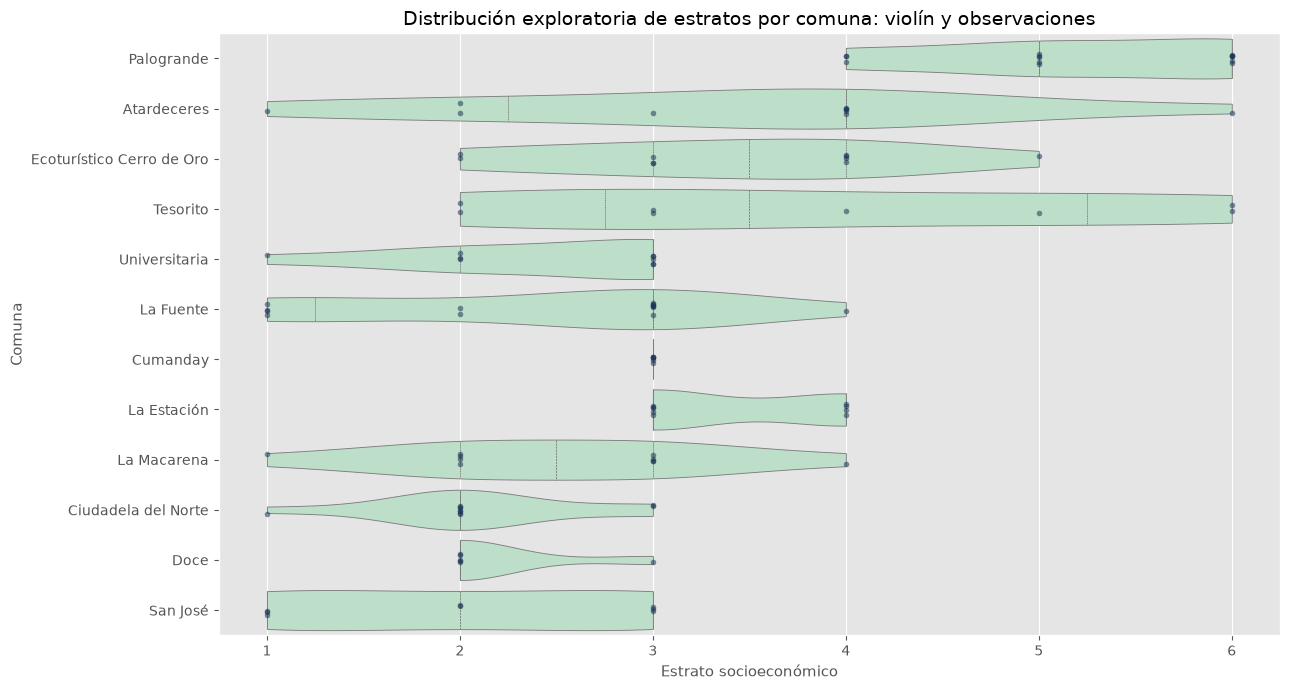

In [17]:
plt.figure(figsize=(13, 7))
sns.violinplot(data=df, x="estrato", y="comuna", order=orden_comunas,
               inner="quartile", cut=0, color="#b7e4c7", density_norm="width")
sns.stripplot(data=df, x="estrato", y="comuna", order=orden_comunas,
              color="#1d3557", alpha=0.55, jitter=0.12, size=4)
plt.title("Distribución exploratoria de estratos por comuna: violín y observaciones")
plt.xlabel("Estrato socioeconómico")
plt.ylabel("Comuna")
plt.xticks(range(1, 7))
plt.tight_layout()
plt.show()

**Interpretación:** los puntos permiten ver los valores realmente observados y el violín resume la concentración estimada. La visualización confirma que Palogrande se concentra en valores altos, mientras que varias comunas presentan mayor presencia de estratos 2 y 3. Dado el tamaño reducido de algunos grupos y la naturaleza ordinal de la variable, el violín se utiliza como complemento visual y no como evidencia de una distribución continua.

## 6. Detección exploratoria de valores atípicos mediante el rango intercuartílico

Se aplica la regla habitual: un valor se marca como posible atípico si está por debajo de Q1 − 1,5 × RIQ o por encima de Q3 + 1,5 × RIQ. Se calcula para el conjunto completo y también se listan los barrios identificados. La detección es estadística y no implica que el dato sea incorrecto.

In [18]:
q1 = df["estrato"].quantile(0.25)
q3 = df["estrato"].quantile(0.75)
riq = q3 - q1
limite_inferior = q1 - 1.5 * riq
limite_superior = q3 + 1.5 * riq

atipicos = df[(df["estrato"] < limite_inferior) | (df["estrato"] > limite_superior)]

print(f"Q1 = {q1:.2f} | Q3 = {q3:.2f} | RIQ = {riq:.2f}")
print(f"Límite inferior = {limite_inferior:.2f}")
print(f"Límite superior = {limite_superior:.2f}")
print("Cantidad de posibles valores atípicos:", len(atipicos))
display(atipicos[["comuna", "barrio", "estrato"]].sort_values(["comuna", "barrio"]))

Q1 = 2.00 | Q3 = 4.00 | RIQ = 2.00
Límite inferior = -1.00
Límite superior = 7.00
Cantidad de posibles valores atípicos: 0


,comuna,barrio,estrato


## 7. Resumen comparativo por comuna

In [19]:
resumen_comunas = (df.groupby("comuna")
                   .agg(numero_barrios=("barrio", "count"),
                        estrato_promedio=("estrato", "mean"),
                        estrato_mediano=("estrato", "median"),
                        estrato_minimo=("estrato", "min"),
                        estrato_maximo=("estrato", "max"),
                        estratos_distintos=("estrato", "nunique"))
                   .sort_values("estrato_promedio", ascending=False))
display(resumen_comunas.round(2))

,numero_barrios,estrato_promedio,estrato_mediano,estrato_minimo,estrato_maximo,estratos_distintos
comuna,,,,,,
Palogrande,14,5.21,5.0,4,6,3
Tesorito,8,3.88,3.5,2,6,5
La Estación,9,3.44,3.0,3,4,2
Atardeceres,10,3.40,4.0,1,6,5
Ecoturístico Cerro de Oro,10,3.40,3.5,2,5,4
Cumanday,6,3.00,3.0,3,3,1
La Macarena,10,2.50,2.5,1,4,4
Universitaria,9,2.44,3.0,1,3,3
La Fuente,14,2.36,3.0,1,4,4


## 8. Conclusiones generales

A partir de los cálculos y las visualizaciones se establecen las siguientes conclusiones:

1. **Predominio del estrato 3:** es la categoría con mayor frecuencia, con 39 de los 114 barrios registrados (34,2 %). Le siguen los estratos 2 (29 barrios; 25,4 %) y 4 (19 barrios; 16,7 %). En conjunto, los estratos 2, 3 y 4 reúnen la mayor parte de los registros.
2. **Centro de la distribución:** la media es aproximadamente 3,08 y la mediana es 3. Esto indica que el centro de la distribución de barrios se encuentra alrededor del estrato 3.
3. **Diferencias entre comunas:** Palogrande presenta el promedio descriptivo más alto (aproximadamente 5,21), mientras que San José presenta el más bajo (2,00). Estas cifras resumen los barrios registrados y no deben interpretarse como promedios de ingresos o de personas.
4. **Concentraciones específicas:** el mapa de calor y las barras apiladas muestran que Palogrande concentra registros en los estratos 4, 5 y 6; San José y Ciudadela del Norte se concentran principalmente en los estratos 1 y 2. Cumanday aparece únicamente con estrato 3 en esta base.
5. **Variabilidad:** las cajas y bigotes permiten comparar medianas y dispersión entre comunas. La composición no es uniforme: algunas comunas reúnen varios estratos, mientras otras presentan una concentración más marcada.
6. **Calidad de los datos:** no se encontraron valores nulos ni filas duplicadas en la revisión inicial. Se normalizaron algunos nombres de comunas que presentaban errores de codificación. La regla del rango intercuartílico debe entenderse como una alerta exploratoria y no como prueba de error en un registro.
7. **Limitaciones:** la base contiene 114 registros de barrios y no incluye población, número de viviendas, área, ingresos ni fecha de actualización. Por ello, no es posible ponderar los resultados por habitantes ni generalizarlos más allá de los registros disponibles.

### Conclusión final

El análisis evidencia que el estrato 3 es el más frecuente entre los barrios incluidos en la base y que existen diferencias claras en la composición de estratos entre comunas de Manizales. Las visualizaciones complementarias —diagrama de cajas y bigotes, mapa de calor, barras apiladas porcentuales, gráfico de puntos y diagrama de violín— permiten examinar la dispersión, las concentraciones y las diferencias entre grupos desde perspectivas distintas. En conjunto, los resultados ofrecen una descripción exploratoria útil, siempre teniendo presente que cada registro corresponde a un barrio y no a una persona o vivienda.